# 6.5 · 绩效归因：超额收益来自哪里

> 绩效指标告诉你"赚了多少"，**绩效归因（attribution）回答"为什么赚/亏"**：
> 是选对了行业（配置），还是行业内选对了股票（选股）？是哪个因子的暴露带来的？
> 归因是研究员理解策略、改进策略、向老板/客户解释业绩的核心能力。

## 一、Brinson 归因（按行业）

Brinson 把超额收益分解为三部分（按行业）：
- **配置效应（allocation）**：$(w_p - w_b) r_b$——超配/低配行业的贡献；
- **选股效应（selection）**：$w_b (r_p - r_b)$——行业内选对个股的贡献；
- **交互效应（interaction）**：$(w_p - w_b)(r_p - r_b)$——配置与选股的交叉。

其中 $w_p/w_b$ 是组合/基准行业权重，$r_p/r_b$ 是组合/基准行业收益。
> 三部分加总 = 组合相对基准的超额收益（这是验证归因正确性的关键）。

## 二、多因子归因（按因子）

用因子风险模型分解收益：
- 组合在各因子上的暴露 $\beta_p$；
- 当期因子收益 $f$；
- **因子贡献 = $\beta_p f$**；
- 剩余无法被因子解释的部分是**特质贡献**。

> 例如：组合有强烈的小市值暴露，当小市值风格上涨时贡献正收益，下跌时拖累。

## 三、Brinson 归因实测（代码在 backtest_lab.attribution）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.library import build_factors
from backtest_lab.attribution import brinson
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
ret = close.pct_change()
facs = build_factors(close, F['$volume'].unstack('instrument'),
                     F['$mkt_cap_ard'].unstack('instrument'),
                     F['$pe_ttm'].unstack('instrument'),
                     F['$pb_lf'].unstack('instrument'))
univ = pd.read_csv(r'C:\Users\gucao\Desktop\Qlib\data\index_universe\000300_sh.csv')
univ['qlib_code'] = univ['qlib_code'].str.upper()
ind_map = dict(zip(univ['qlib_code'], univ['industry']))
i = -2
scores = facs['SMB 小市值'].iloc[i]
top = scores.dropna().nlargest(30)
wp = pd.Series(0.0, index=scores.index); wp[top.index] = 1/30
wb = pd.Series(1.0/len(scores), index=scores.index)
r = ret.iloc[i+1]; industry = pd.Series(ind_map, index=scores.index)
br = brinson(wp, wb, r, industry)
print(br.round(5))
print('\n三部分合计: %.5f  实际超额: %.5f' %
      (br['合计'].sum(), (wp*r).sum()-(wb*r).sum()))

[12900:MainThread](2026-10-30 01:52:42,104) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[12900:MainThread](2026-10-30 01:52:43,538) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[12900:MainThread](2026-10-30 01:52:43,539) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


           配置       选股       交互       合计
行业                                      
信息技术 -0.00119  0.00259  0.00033  0.00174
公用事业 -0.00084 -0.00084  0.00084 -0.00084
医疗保健 -0.00035 -0.00161 -0.00322 -0.00518
可选消费  0.00009  0.00130 -0.00054  0.00085
工业    0.00006  0.00126 -0.00010  0.00122
房地产  -0.00038 -0.00018 -0.00074 -0.00130
日常消费 -0.00032  0.00079 -0.00029  0.00018
材料    0.00120 -0.00065  0.00046  0.00101
能源   -0.00046 -0.00046  0.00046 -0.00046
通讯服务  0.00001 -0.00020 -0.00020 -0.00040
金融   -0.00006 -0.00383  0.00077 -0.00313

三部分合计: -0.00632  实际超额: -0.00632


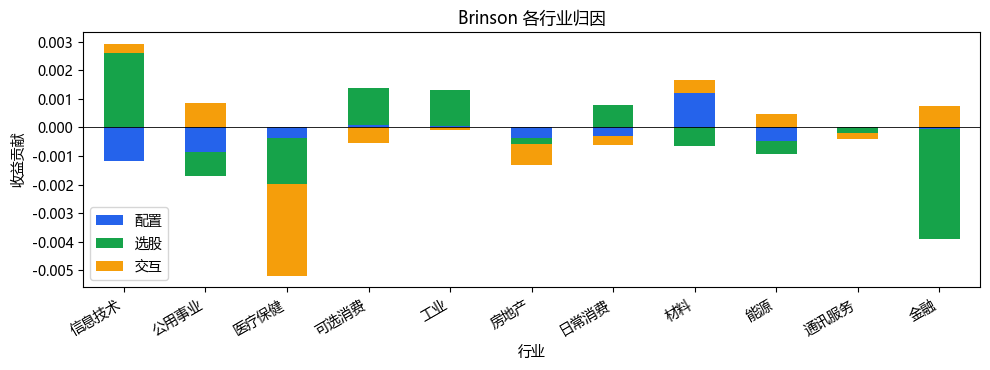

In [2]:
# 各行业配置/选股/交互 堆叠图
br_plot = br[['配置','选股','交互']]
br_plot.plot(kind='bar', stacked=True, figsize=(10, 3.8),
             color=['#2563eb','#16a34a','#f59e0b'])
plt.axhline(0, color='black', lw=.6)
plt.title('Brinson 各行业归因'); plt.ylabel('收益贡献')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

## 四、多因子归因实测

In [3]:
from backtest_lab.attribution import factor_attribution
from portfolio_lab.risk import factor_risk_model
exp_names = ['SMB 小市值', 'EP 盈利收益率', 'BP 账面市值比',
             'REV5 短期反转', '低波60']
exposures = {k: facs[k].rank(axis=1, pct=True)*2-1 for k in exp_names}
model = factor_risk_model(ret, exposures)
fr_day = model['factor_returns'].iloc[i]
exposures_day = {k: exposures[k].iloc[i] for k in exp_names}
fa = factor_attribution(wp, fr_day, exposures_day)
print(fa.round(4))
print('\n因子贡献合计 %.5f，特质贡献 %.5f' %
      (fa['贡献'].sum(), (wp*r).sum()-(wb*r).sum()-fa['贡献'].sum()))

             组合暴露    因子收益      贡献
SMB 小市值    0.9033 -0.0079 -0.0071
EP 盈利收益率  -0.3849 -0.0054  0.0021
BP 账面市值比   0.0022 -0.0048 -0.0000
REV5 短期反转  0.2320 -0.0026 -0.0006
低波60      -0.0702 -0.0155  0.0011

因子贡献合计 -0.00452，特质贡献 -0.00180


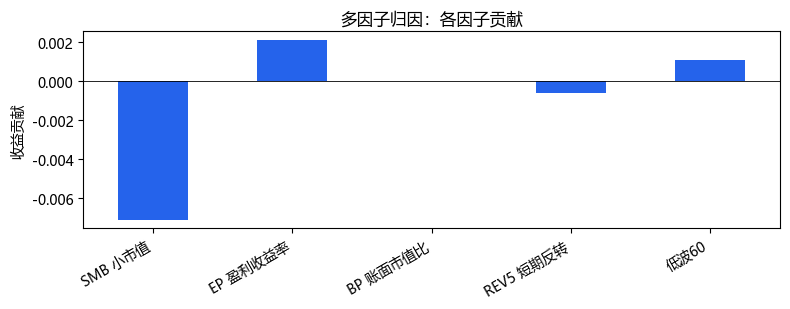

In [4]:
fa['贡献'].plot(kind='bar', figsize=(8, 3.2), color='#2563eb')
plt.axhline(0, color='black', lw=.6)
plt.title('多因子归因：各因子贡献'); plt.ylabel('收益贡献')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

## 五、归因的注意事项

- 归因结果依赖风险模型/行业划分，不同模型结果略有差异；
- 单期归因噪声大，要看**累计、长期归因**，结论才稳定；
- 归因要能解释主要收益来源；如果大量收益来自"意外/残差"，说明策略理解不充分；
- 归因的目的是**改进**：发现配置/选股/因子暴露的问题，针对性优化。

> 实盘还要把"实际成交 vs 信号"的执行归因（滑点、未成交）纳入。

## 六、小结与面试要点

- Brinson：配置（行业）、选股（行业内）、交互，三部分加总=超额。
- 多因子归因：因子暴露×因子收益=因子贡献，剩余为特质。
- 归因要长期累计、能解释主要来源、用于改进策略。

**面试高频：**
- Brinson 归因怎么分解超额？（答：配置、选股、交互三效应）
- 配置效应和选股效应的区别？（答：配置是行业权重，选股是行业内个股）
- 多因子归因怎么做？（答：组合因子暴露×因子收益，剩余是特质）
- 归因结果怎么用？（答：理解收益来源、发现问题、改进策略）

## 动手练习
1. 对一整年累计做 Brinson 归因，看主要贡献行业；
2. 比较不同组合（Top30 vs Top100）的因子归因；
3. 思考：如果一个策略的超额主要来自特质残差，说明什么。

---
模块 6 完成！下一模块 **7. 实盘工程：交易系统、订单管理、监控、部署**。